**TAREA 1: CLASIFICACIÓN**
-

A lo largo de este notebook se desarrolla la tarea de clasificación del proyecto. Mi objetivo es predecir la variable que diferencia tres tipos de estudiantes: Abandono, Matriculado y Graduado.

Durante el desarrollo de esta tarea se llevará a cabo el siguiente proceso ordenado: primero se definen las variables que entran en el modelo, después se separa train/test una sola vez con aleatoriedad, se construyen los pipelines de preprocesado, se entrenan baselines y modelos, y finalmente se evalúa e interpreta.

**1. Carga de datos y definición de variables**

Cargo los datos y todas las librerías que voy a usar durante el desarrollo de esta tarea. Me apoyo en funciones desarrolladas en otros archivos.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

from data_loading import cargar_dataset, obtener_features_clasificacion
from preprocessing import separar_tipos, construir_preprocesador, obtener_nombres_features
from classification import construir_pipelines_clasificacion, construir_baseline_clasificacion, evaluar_clasificacion
from utils import extraer_importancias

df = cargar_dataset("../data/student_success.csv")
df.head()

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


Cargo el dataset y defino los bloques de variables tal como se hizo en el EDA. Esto me permite tener claro qué columnas entran como predictores en clasificación.

**2. Selección formal de variables para clasificación**

Defino los bloques de variables que usaré como predictores en clasificación. Voy a trabajar con 2 versiones del dataset. Estas se presentan a continuación:

- **Versión base**: solo variables demográficas, de acceso/contexto previo, socioeconómicas/administrativas y macroeconómicas. Es decir, información disponible en el momento del acceso del estudiante.
- **Versión extendida**: añade el bloque de rendimiento del primer semestre.

Al trabajar con 2 versiones diferentes del dataset puedo estudiar cómo y cuánto influyen las variables o features relacionadas con el rendimiento académico del alumno en la predicción. Entre las variables del rendimiento académico no incluyo las del segundo semestre. Esto se debe a que quiero realizar una predicción realista y, por lo tanto, quiero predecir el resultado del estudiante con variables del primer semestre como muy tarde.

In [2]:
#obtengo las features de clasificación con funciones de src
features_base, features_extendida = obtener_features_clasificacion()

target = "objetivo"

print(f"Variables en versión base: {len(features_base)}"
	  f"\nVariables en versión extendida: {len(features_extendida)}")

Variables en versión base: 24
Variables en versión extendida: 30


Compruebo que las variables seleccionadas existen en el dataset y no me dejo ninguna por error.

In [3]:
#comprobación
for col in features_extendida:
    if col not in df.columns:
        print(f"ERROR: {col} no esta en el dataset")

print("Todas las variables existen en el dataset.")

Todas las variables existen en el dataset.


**3. Identificación de variables numéricas y categóricas**

Debo preprocesar mi dataset para que el modelo aprenda únicamente información relevante. Para ello debo codificar las variables categóricas y estandarizar las numéricas. 

Antes de realizar ese apartado identificaré mis features numéricas y categóricas. 

In [4]:
#identifico numéricas y categóricas usando la función de src
categoricas, numericas = separar_tipos(df, features_extendida)

print(f"Categóricas ({len(categoricas)}): {categoricas}"
	  f"\nNuméricas ({len(numericas)}): {numericas}")

Categóricas (17): ['estado_civil', 'nacionalidad', 'desplazado', 'necesidades_educativas_especiales', 'genero', 'internacional', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'deudor', 'matricula_al_dia', 'becado']
Numéricas (13): ['edad_al_matricularse', 'orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'tasa_desempleo', 'tasa_inflacion', 'pib', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion']


**4. Separación train/test**

Separo los datos en train y test una sola vez. Para corregir el desbalanceo que observé en el EDA usaré estratificación. De esta manera, la proporción de clases se mantiene. Por otra parte, el conjunto de observaciones de test solo se usará al final para la evaluación definitiva.

Fijo una semilla (random_state=42) para que los resultados sean reproducibles. 

La separación se hace de manera aleatoria con sklearn. 

In [5]:
#separo features y target para la versión extendida
X = df[features_extendida]
y = df[target]

#split 80/20 con estrataficación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} observaciones"
	  f"\nTest: {X_test.shape[0]} observaciones")

print("\n - Proporción de clases en train: ", "\n", y_train.value_counts(normalize=True).round(3) * 100)
print("\n - Proporción de clases en test: ", "\n", y_test.value_counts(normalize=True).round(3) * 100)

Train: 3539 observaciones
Test: 885 observaciones

 - Proporción de clases en train:  
 objetivo
graduado       49.9
abandono       32.1
matriculado    17.9
Name: proportion, dtype: float64

 - Proporción de clases en test:  
 objetivo
graduado       49.9
abandono       32.1
matriculado    18.0
Name: proportion, dtype: float64


Compruebo que la estratificación ha funcionado correctamente. Las proporciones de las tres clases deben ser prácticamente iguales en train y test.

**5. Construcción del pipeline de preprocesado**

Construyo un pipeline que aplique el preprocesado necesario. El pipeline me ayuda a evitar el data leakage.

Aplico el preprocesado al pipeline para evitar fugas de información entre train y test (data leakage). Por una parte, las variables numércias las estandarizo con StandarScaler. Por otro lado, las variables categóricas las codifico de manera binaria a One Hot Encoding.

In [6]:
#construyo el preprocesador usando la función de src
preprocesador = construir_preprocesador(numericas, categoricas)

print(f"Variables numéricas en pipeline: {len(numericas)}"
	  f"\nVariables categóricas en pipeline: {len(categoricas)}")

Variables numéricas en pipeline: 13
Variables categóricas en pipeline: 17


**6. Baseline: clasificador por clase mayoritaria**

Antes de entrenar modelos reales, necesito un baseline con el que comparar el rendimiento de mi modelo. Para ello, construyo el más simple. Este baseline es el clasificador de clase mayoritaria, que siempre predice la clase más frecuente.

Si mis modelos no superan este baseline, significaría que no aportan nada respecto a simplemente predecir siempre "graduado".

In [7]:
#baseline usando la función de src
baseline = construir_baseline_clasificacion()
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

metricas_bl, m = evaluar_clasificacion(y_test, y_pred_baseline)

print("-"*8, "Baseline (clase mayoritaria)", "-"*8)
print(f"Accuracy: {metricas_bl['accuracy']:.3f}"
	  f"\nMacro F1: {metricas_bl['macro_f1']:.3f}"
	  f"\nBalanced Accuracy: {metricas_bl['balanced_accuracy']:.3f}")

-------- Baseline (clase mayoritaria) --------
Accuracy: 0.499
Macro F1: 0.222
Balanced Accuracy: 0.333


El baseline da un macro F1 de 0.222 y una accuracy del 49.9%. La accuracy puede confundirme debido a que simplemente refleja que la clase mayoritaria es graduado. El macro F1 deja claro que predecir siempre la misma clase no tiene un gran rendimiento. Uso macro F1 como métrica principal porque reparte atención entre las tres clases por igual.

**7. Modelo 1: Regresión Logística Multinomial**

El primer modelo que entreno es una regresión logística multinomial. 

Utilizo validación cruzada estratificada, para mantener la proporción de clases, con 5 folds para estimar el rendimiento del modelo sin tocar el test. La métrica principal es el macro F1.

In [8]:
#construyo los pipelines desde src
pipelines = construir_pipelines_clasificacion(preprocesador)

#validación cruzada estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_lr = pipelines["Logistica"]
scores_lr = cross_val_score(pipe_lr, X_train, y_train, cv=cv, scoring="f1_macro")

print("-"*8, "Regresión Logística (CV)", "-"*8)
print(f"Macro F1 por fold: {scores_lr.round(3)}"
	  f"\nMacro F1 medio: {scores_lr.mean():.3f} con error de +- {scores_lr.std():.3f}")

-------- Regresión Logística (CV) --------
Macro F1 por fold: [0.67  0.669 0.69  0.656 0.679]
Macro F1 medio: 0.673 con error de +- 0.011


**8. Modelo 2: Random Forest**

El segundo modelo es un Random Forest, que es un ensemble de árboles de decisión. Es un modelo no lineal complejo que corrige la varianza del overfitting y la correlación de otros modelos como Bagging. Lo comparo con la regresión logística para ver si el rendimiento crece al usar un modelo más flexible.

In [9]:
pipe_rf = pipelines["Random Forest"]
scores_rf = cross_val_score(pipe_rf, X_train, y_train, cv=cv, scoring="f1_macro")

print("-"*8, "Random Forest (CV)", "-"*8)
print(f"Macro F1 por fold: {scores_rf.round(3)}"
	  f"\nMacro F1 medio: {scores_rf.mean():.3f} con error de +- {scores_rf.std():.3f}")

-------- Random Forest (CV) --------
Macro F1 por fold: [0.627 0.631 0.652 0.638 0.613]
Macro F1 medio: 0.632 con error de +- 0.013


**9. Modelo 3: Gradient Boosting**

Finalmente, como tercer modelo pruebo Gradient Boosting, otro ensemble basado en árboles. Este modelo construye árboles de forma secuencial, donde cada árbol intenta corregir los errores del anterior. Teóricamente, da mejor rendimiento que otros modelos de ensemble de árboles como Bagging o RF.

In [10]:
pipe_gb = pipelines["Gradient Boosting"]
scores_gb = cross_val_score(pipe_gb, X_train, y_train, cv=cv, scoring="f1_macro")

print("-"*8, "Gradient Boosting (CV)", "-"*8)
print(f"Macro F1 por fold: {scores_gb.round(3)}"
	  f"\nMacro F1 medio: {scores_gb.mean():.3f} con error de +- {scores_gb.std():.3f}")

-------- Gradient Boosting (CV) --------
Macro F1 por fold: [0.647 0.666 0.67  0.687 0.693]
Macro F1 medio: 0.673 con error de +- 0.016


**10. Comparación de modelos en validación cruzada**

Comparo los tres modelos usando los resultados de validación cruzada. Esta comparación se hace exclusivamente sobre train, sin tocar el test.

In [11]:
#tabla comparativa
comparacion = pd.DataFrame({
    "Modelo": ["Logística Multinomial", "Random Forest", "Gradient Boosting"],
    "Macro F1 medio": [scores_lr.mean(), scores_rf.mean(), scores_gb.mean()],
    "Desviación": [scores_lr.std(), scores_rf.std(), scores_gb.std()]
})

comparacion = comparacion.sort_values("Macro F1 medio", ascending=False)
comparacion.round(3)

,Modelo,Macro F1 medio,Desviación
0,Logística Multinomial,0.673,0.011
2,Gradient Boosting,0.673,0.016
1,Random Forest,0.632,0.013


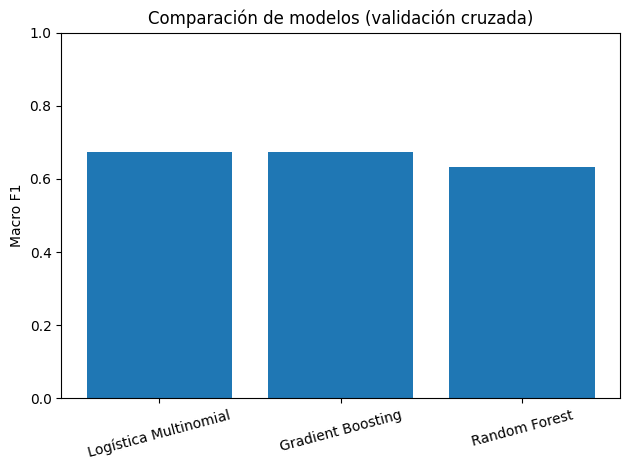

In [12]:
#gráfico comparativo
plt.bar(comparacion["Modelo"], comparacion["Macro F1 medio"])
plt.ylabel("Macro F1")
plt.title("Comparación de modelos (validación cruzada)")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

A partir de esta comparación selecciono el mejor modelo para la evaluación final en test. La decisión se basa en el macro F1 medio obtenido en validación cruzada. Gradient Boosting y regresión logística tienen el mismo macro F1, pero la desviación en la regresión logística multinomial es ligeramente menor. Por lo tanto, creo que el modelo con mejor rendimiento será la regresión logítica multinomial.

**11. Evaluación final en test con el mejor modelo**

Ahora sí toco el test por primera y única vez. Entreno el mejor modelo con todo el train y evalúo sobre el test para obtener las métricas definitivas.

In [13]:
#selecciono el mejor modelo según CV
resultados_cv = {
    "Logistica": (pipe_lr, scores_lr.mean()),
    "Random Forest": (pipe_rf, scores_rf.mean()),
    "Gradient Boosting": (pipe_gb, scores_gb.mean())
}

nombre_mejor = max(resultados_cv, key=lambda k: resultados_cv[k][1])
mejor_pipe = resultados_cv[nombre_mejor][0]

print(f"Mejor modelo según CV: {nombre_mejor}")

#entreno con todo el train
mejor_pipe.fit(X_train, y_train)

#predicciones en test
y_pred = mejor_pipe.predict(X_test)

Mejor modelo según CV: Logistica


Efectivamente, se cumple mi predicción. La regresión logística multinomial es el mejor modelo de clasificación según la métrica macro F1. 

Ahora estudio más en detalle el rendimiento del modelo escogido. 

In [14]:
#métricas finales en test usando la función de src
metricas_test, reporte = evaluar_clasificacion(y_test, y_pred)

print(f"- Evaluación final en test: {nombre_mejor} ")
print(f"Accuracy: {metricas_test['accuracy']:.3f}"
	  f"\nMacro F1: {metricas_test['macro_f1']:.3f}"
	  f"\nBalanced Accuracy: {metricas_test['balanced_accuracy']:.3f}")

print("\n- Métricas de clasificación:")
print(reporte)

- Evaluación final en test: Logistica 
Accuracy: 0.751
Macro F1: 0.664
Balanced Accuracy: 0.658

- Métricas de clasificación:
              precision    recall  f1-score   support

    abandono       0.80      0.75      0.77       284
    graduado       0.79      0.91      0.84       442
 matriculado       0.46      0.31      0.37       159

    accuracy                           0.75       885
   macro avg       0.68      0.66      0.66       885
weighted avg       0.73      0.75      0.74       885



**12. Matriz de confusión**

La matriz de confusión me permite ver concretamente dónde acierta y dónde se equivoca el modelo. Es una métrica bastante informativa, pero debo estar atento a las características de mi dataset para que no me lleve a conclusiones erróneas.

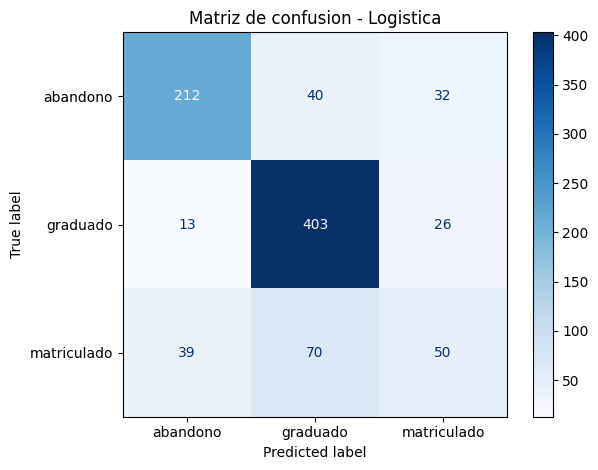

In [15]:
#matriz de confusion
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=mejor_pipe.classes_)
disp.plot(cmap="Blues")
plt.title(f"Matriz de confusion - {nombre_mejor}")
plt.tight_layout()
plt.show()

La matriz es claramente diagonal, lo que indica un buen rendimiento general. Sin embargo, el modelo presenta diferencias importantes entre clases. Para la clase graduado el modelo funciona muy bien, pero para la clase matriculado el rendimiento es considerablemente bajo. Por otro lado, en términos absolutos hay más errores en la clase graduado, lo cual es lógico dada la proporción de clases en el dataset. Sin embargo, en términos relativos es la clase mejor modelada. 

**13. Comparación: versión base vs versión extendida**

Ahora comparo cuánto mejora el modelo al añadir las variables de rendimiento del primer semestre. Para ello entreno el mismo tipo de modelo pero usando solo las variables de la versión base.

Esta comparación es muy útil ya que nos dice si el desempeño temprano del estudiante aporta información predictiva relevante o si las variables de entrada ya son suficientes.

In [16]:
#versión base: preprocesador y pipelines desde src
cat_base, num_base = separar_tipos(df, features_base)
preprocesador_base = construir_preprocesador(num_base, cat_base)

X_train_base = X_train[features_base]
X_test_base = X_test[features_base]

pipelines_base = construir_pipelines_clasificacion(preprocesador_base)

scores_lr_base = cross_val_score(pipelines_base["Logistica"], X_train_base, y_train, cv=cv, scoring="f1_macro")
scores_rf_base = cross_val_score(pipelines_base["Random Forest"], X_train_base, y_train, cv=cv, scoring="f1_macro")

print("-"*8, "Versión BASE (sin 1er semestre)", "-"*8)
print(f"Logística Macro F1: {scores_lr_base.mean():.3f} con error de +- {scores_lr_base.std():.3f}"
	  f"\nRandom Forest Macro F1: {scores_rf_base.mean():.3f} con error de +- {scores_rf_base.std():.3f}")

print("\n", "-"*8, "Versión EXTENDIDA (con 1er semestre)", "-"*8)
print(f"Logística Macro F1: {scores_lr.mean():.3f} con error de +- {scores_lr.std():.3f}"
	  f"\nRandom Forest Macro F1: {scores_rf.mean():.3f} con error de +- {scores_rf.std():.3f}")

-------- Versión BASE (sin 1er semestre) --------
Logística Macro F1: 0.536 con error de +- 0.008
Random Forest Macro F1: 0.495 con error de +- 0.017

 -------- Versión EXTENDIDA (con 1er semestre) --------
Logística Macro F1: 0.673 con error de +- 0.011
Random Forest Macro F1: 0.632 con error de +- 0.013


La diferencia entre las dos versiones muestra cuánto aporta el rendimiento del primer semestre. Si el salto es grande, el primer semestre es clave para predecir la trayectoria. Como se puede observar, hay un salto de poco más del 10% global de mejoría del rendimiento. Por lo tanto, parece que la versión extendida nos aporta mayor rendimiento y, por consecuencia, el desempeño temprano del estudiante nos aporta información predictiva acerca de su futuro.

**14. Importancia de variables**

Para interpretar qué variables son más relevantes para la predicción, extraigo la importancia de variables del modelo. Esto me permitirá identificar qué factores están más asociados con el abandono, la permanencia o la graduación del alumno.

Estudio la importancia de las variables según los coeficientes de la regresión logística multinomial.

In [17]:
#importancia de variables usando funciones de src
mejor_pipe.fit(X_train, y_train)

nombres_features = obtener_nombres_features(mejor_pipe.named_steps["preprocesador"], numericas, categoricas)
modelo_interno = mejor_pipe.named_steps["modelo"]
importancias, tipo_importancia = extraer_importancias(modelo_interno)

imp_df = pd.DataFrame({
    "variable": nombres_features,
    "importancia": importancias
}).sort_values("importancia", ascending=False)

print("Top 15 variables más importantes: \n", imp_df.head(15))

Top 15 variables más importantes: 
                                               variable  importancia
10                          asignaturas_1sem_aprobadas     1.417180
167                         ocupacion_madre_estudiante     0.861843
208                     ocupacion_padre_otra_situacion     0.791513
65                 curso_animacion_y_diseno_multimedia     0.779848
170                     ocupacion_madre_otra_situacion     0.773615
54   modo_solicitud_estudiante_internacional_licenc...     0.757147
121      cualificacion_madre_educacion_superior_master     0.733738
67                              curso_educacion_basica     0.652467
173               ocupacion_madre_personal_de_limpieza     0.648868
79   curso_tecnologias_de_produccion_de_biocombusti...     0.634587
8                        asignaturas_1sem_matriculadas     0.618632
234                                matricula_al_dia_no     0.613757
235                                matricula_al_dia_si     0.574279
169  ocupaci

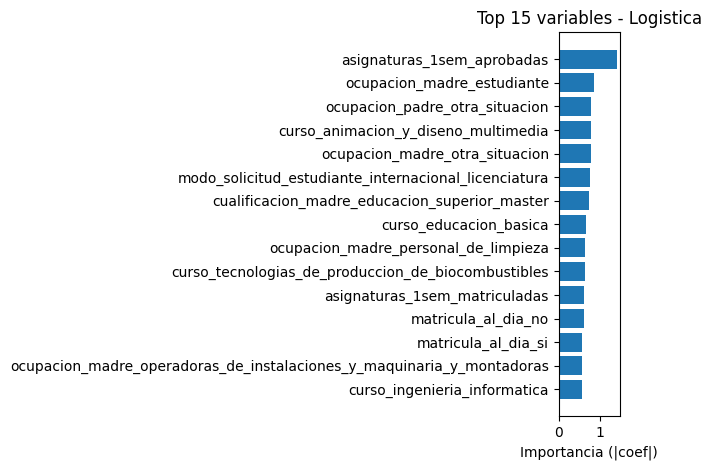

In [18]:
#gráfico de las 15 variables más importantes
top15 = imp_df.head(15)
plt.barh(top15["variable"], top15["importancia"])
plt.xlabel(tipo_importancia)
plt.title(f"Top 15 variables - {nombre_mejor}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**15. Interpretación de resultados de clasificación**

A continuacion se presenta el resumen de la tarea de clasificación.

En líneas generales, el modelo final supera claramente al baseline trivial (clase mayoritaria), con un macro F1 de 0.657 frente a 0.222. Uso macro F1 como métrica principal porque, al haber desbalanceo entre clases, la accuracy me da una imagen engañosa del rendimiento.

Por una parte, la comparación entre modelos en validación cruzada muestra rendimientos similares entre regresión logística y Gradient Boosting (ambos alrededor de 0.673 en macro F1, pero con una ligera diferencia en cuanto a la desviación típica). El criterio automático de selección por macro F1 medio en CV escoge Gradient Boosting para la evaluación final en test.

Por otro lado, el hecho de añadir las variables del primer semestre supone un salto grande en rendimiento: el macro F1 pasa de estar en torno al 0.5 en la versión base al 0.67 en la versión extendida. Por lo tanto, el rendimiento temprano del estudiante es, con diferencia, el bloque más informativo para predecir su trayectoria. Este último hecho se ve reflejado en las gráficas mostradas anteriormente. En cuanto a la importancia de las variables relacionadas con el rendimiento académico del estudiante, la más importante es asignaturas_1sem_aprobadas, seguida de matricula_al_dia y nota_media_1sem.

En cuanto al rendimiento del modelo final respecto a las diferentes clases, la matriz de confusión muestra que la clase peor predicha es matriculado, con un F1=0.37. Esto tiene sentido dado que es la clase más ambigua, porque un estudiante matriculado puede acabar graduándose o abandonando. Las confusiones se concentran entre matriculado y las otras dos clases, no tanto entre abandono y graduado.